# CICIDS2017 Learning when Labels Are Scarce Lab2
This notebook loads, cleans, trains, evaluates, and saves a binary intrusion detection workflow.

In [9]:
import random
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Configure the experiment

In [10]:
project_dir = Path.cwd()
data_dir = project_dir / "data"
# Keep full-data runs for final results; sampling is useful when checking code quickly.
USE_SAMPLE = False
SAMPLE_FRAC = 0.25
csv_files = sorted(data_dir.glob("*.csv"))
print(f"Found {len(csv_files)} CSV files in data/")
for path in csv_files:
    print(" -", path.name)


Found 8 CSV files in data/
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


## 2. Load and clean the CSV files

Used Latin-1 fallback for Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Cleaned dataset shape: (2813800, 81)

Dataset columns:
['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Pac

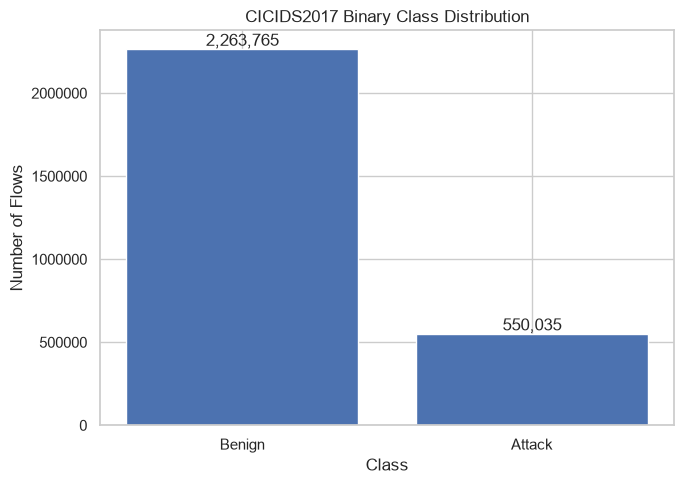

In [11]:
frames = []
for csv_path in csv_files:
    try:
        # UTF-8 is preferred; the fallback handles the older CICIDS2017 file with Latin-1 bytes.
        frame = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        frame = pd.read_csv(csv_path, encoding="latin1", low_memory=False)
        print(f"Used Latin-1 fallback for {csv_path.name}")

    # Normalize headers before looking for Label because some files contain leading spaces.
    frame.columns = [str(col).strip() for col in frame.columns]
    label_col = next((col for col in frame.columns if col.lower() == "label"), None)
    if frame.empty or label_col is None:
        print(f"Skipping {csv_path.name}: no usable label column")
        continue
    if label_col != "Label":
        frame = frame.rename(columns={label_col: "Label"})
    frames.append(frame)

if not frames:
    raise ValueError("No valid CICIDS2017 CSV files were found in the data folder.")

# Combine the valid files into one flow-level dataset for binary classification.
df = pd.concat(frames, ignore_index=True)

# Identifiers and timestamps can identify a capture rather than describe general traffic behavior.
metadata_cols = ["Flow ID", "Source IP", "Destination IP", "Timestamp"]
df = df.drop(columns=[col for col in metadata_cols if col in df.columns], errors="ignore")

# Remove exact duplicates and convert infinite measurements to missing values.
df = df.drop_duplicates().replace([np.inf, -np.inf], np.nan)
for col in df.columns:
    if col != "Label":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# The lab uses binary classification: benign traffic is 0 and every attack type is 1.
df["Label"] = df["Label"].astype(str).str.strip().apply(lambda label: 0 if label == "BENIGN" else 1)
if USE_SAMPLE:
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED)
print("Cleaned dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nLabel distribution:")
print(df["Label"].value_counts().sort_index())

# Plot binary class distribution
label_counts = df["Label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Benign", "Attack"],
    [
        label_counts.get(0, 0),
        label_counts.get(1, 0)
    ]
)

plt.xlabel("Class")
plt.ylabel("Number of Flows")
plt.title("CICIDS2017 Binary Class Distribution")

# Disable scientific notation on Y-axis
plt.ticklabel_format(
    style="plain",
    axis="y"
)

# Add exact count above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 3. Create stratified train, validation, and test sets

In [12]:
X = df.drop(columns=["Label"])
y = df["Label"].astype(int)
# Stratification keeps the benign/attack ratio similar in all three partitions.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)
print("Train/validation/test sizes:", len(X_train), len(X_val), len(X_test))

Train/validation/test sizes: 1688280 562760 562760


## 4. Creating the 1%, 5% and 10% "few-label" splits

In [ ]:
# Label budgets specify the fraction of the training rows whose labels are available.
LABEL_BUDGETS = [0.01, 0.05, 0.10]

# Keep each budget in its own split so all experiments use the same deterministic setup.
few_label_splits = {}

for budget in LABEL_BUDGETS:
    # Stratified sampling preserves the benign/attack ratio in the labelled subset.
    X_labelled, X_unlabelled, y_labelled, _ = train_test_split(
        X_train,
        y_train,
        train_size=budget,
        random_state=SEED,
        stratify=y_train,
    )

    # Store only the labelled data and unlabeled features; the hidden labels are discarded.
    few_label_splits[budget] = {
        "X_labelled": X_labelled.copy(),
        "y_labelled": y_labelled.copy(),
        "X_unlabelled": X_unlabelled.copy(),
    }

    print(
        f"{budget:.0%} budget: "
        f"{len(X_labelled):,} labelled rows, "
        f"{len(X_unlabelled):,} unlabelled rows"
    )

#The validation set remains fully labelled and is used for model comparison/tuning.
#The test set remains fully labelled and untouched until the final evaluation.

1% budget: 16,882 labelled rows, 1,671,398 unlabelled rows
5% budget: 84,414 labelled rows, 1,603,866 unlabelled rows
10% budget: 168,828 labelled rows, 1,519,452 unlabelled rows
The validation set remains fully labelled and is used for model comparison/tuning.
The test set remains fully labelled and untouched until the final evaluation.


## 5. Recreate the baselines using the above Splits

In [18]:
# Use one consistent plain classifier for the full-label and few-label baselines.
# Imputation and scaling are fitted separately within each training pipeline.
def make_baseline_model():
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            (
                "classifier",
                LogisticRegression(
                    max_iter=1000,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    )

def evaluate_model(model, X_eval, y_eval):
    # FAR is the fraction of benign flows incorrectly classified as attacks.
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]
    tn, fp, _, _ = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1],
    ).ravel()

    return {
        "accuracy": accuracy_score(y_eval, predictions),
        "macro_f1": f1_score(y_eval, predictions, average="macro"),
        "recall": recall_score(y_eval, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, probabilities),
        "far": fp / (fp + tn) if (fp + tn) else 0.0,
    }

In [19]:
baseline_results = []

# Upper baseline: all training labels available

full_label_model = make_baseline_model()
full_label_model.fit(X_train, y_train)

# Use VALIDATION during development.
full_label_metrics = evaluate_model(
    full_label_model,
    X_val,
    y_val
)

baseline_results.append({
    "method": "Full-label baseline",
    "label_budget": 1.0,
    **full_label_metrics
})

# Lower baselines: only 1%, 5%, or 10% labels available

for budget in LABEL_BUDGETS:

    split = few_label_splits[budget]

    labelled_model = make_baseline_model()

    # Only labelled samples are used here.
    # The unlabelled pool is deliberately ignored.
    labelled_model.fit(
        split["X_labelled"],
        split["y_labelled"]
    )

    labelled_metrics = evaluate_model(
        labelled_model,
        X_val,
        y_val
    )

    baseline_results.append({
        "method": "Labelled-only baseline",
        "label_budget": budget,
        **labelled_metrics,
    })


baseline_results_df = pd.DataFrame(
    baseline_results
)

display(
    baseline_results_df.round(4)
)

,method,label_budget,accuracy,macro_f1,recall,roc_auc,far
0,Full-label baseline,1.00,0.9193,0.8858,0.9667,0.9801,0.0923
1,Labelled-only baseline,0.01,0.9270,0.8949,0.9572,0.9839,0.0803
2,Labelled-only baseline,0.05,0.9140,0.8790,0.9607,0.9779,0.0973
3,Labelled-only baseline,0.10,0.9148,0.8799,0.9614,0.9786,0.0965


## 6. Pseudo-Labelling